<a href="https://colab.research.google.com/github/Existanze54/sirius-machine-learning-2026/blob/main/Homeworks/HW2_kNN_LinReg_GT25.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашка 2. k-Nearest Neighbors and Linear Regression

### imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neighbors import KNeighborsRegressor as kNN
from sklearn.linear_model import LinearRegression as LinReg
from sklearn.linear_model import RidgeCV

from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import train_test_split

from sklearn.pipeline import Pipeline

### Заметка про пайплайны

В `sklearn` можно объединить предобработку данных и обучение модели в единый объект — `Pipeline`. Иногда это упрощает код. Например, полиномиальную регрессию (линейную регрессию с предварительным добавлением признаков, возведенных в степени от 2 до *n*) можно оформить так:

In [2]:
pipe = Pipeline([
    ('poly', PolynomialFeatures(degree=3)),
    ('scale', StandardScaler()),
    ('reg', LinReg()),
])

`Pipeline` по умолчанию принимает список кортежей — имя шага и соответствующий объект. Эти объекты применяются к данным последовательно, в порядке их указания: вывод одного шага становится входом следующего. У `Pipeline` есть методы `.fit` и `.predict`, так что его можно использовать как обычную модель.

## Задача 1. Визуальная оценка

### Генерация данных

В этой задаче мы не будем делить данные на обучающую и тестовую выборки и считать метрики качества. Вместо этого оценим модели визуально, чтобы развить интуицию о том, как они работают. Для начала сгенерируем интересную функцию.

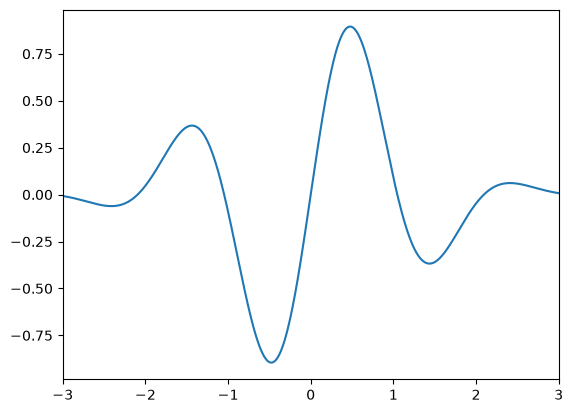

In [2]:
f = lambda x: np.sin(3*x) * np.exp(-(x/1.5)**2)

x = np.arange(-3, 3.01, 0.01)
y = f(x)

plt.plot(x, y)
plt.xlim([-3, 3])
plt.show()

Для обучения возьмем случайные точки из нужного диапазона и добавим к ним нормальный шум — реальные данные почти всегда содержат погрешности.

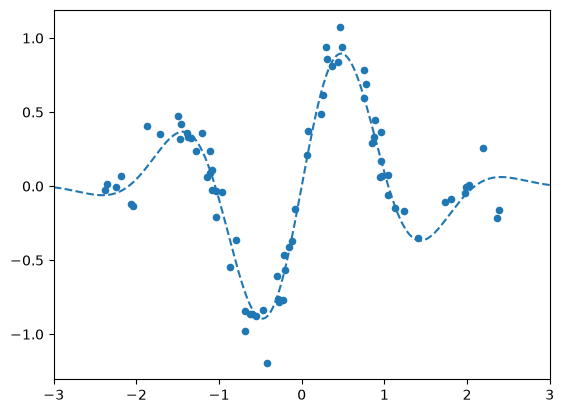

In [3]:
n_points = 75
np.random.seed(3)


x_train = np.random.uniform(-2.5, 2.51, n_points)
y_train = f(x_train) + np.random.normal(0, 0.15, n_points)

plt.plot(x, y, '--')
plt.scatter(x_train, y_train, s=20)

plt.xlim([-3, 3])
plt.show()

### Ваше решение

Осуществите предсказания методами kNN и полиномиальной регрессии (в последнем случае используйте `RidgeCV` как финальный шаг пайплайна). Обучайте модели строго на `x_train`. Визуализируйте результаты предсказаний на полном диапазоне `x`, добавив на график исходную функцию (`plt.plot(x, y)`) и обучающие точки (`plt.scatter(x_train, y_train)`). Подберите число ближайших соседей и степень полинома на глаз.

In [ ]:
# your code here

pipe_KNN = Pipeline([
    ('kNN', kNN()),
    ('scale', StandardScaler()),
    ('reg', LinReg())
    ])


pipe = Pipeline([
    ('poly', PolynomialFeatures(degree=3)),
    ('scale', StandardScaler()),
    ('reg', LinReg()),
])

## Задача 2. Предсказание растворимости молекул

Поработаем с известным датасетом [ESOL](https://www.kaggle.com/c/drug-solubility-challenge/data), содержащим данные о растворимости лекарствоподобных и других органических молекул в воде. Обычно молекулярные признаки вычисляют с помощью `rdkit` и других хемоинформатических инструментов, но в этом наборе данные уже подготовлены заранее.

In [ ]:
! wget -q https://raw.githubusercontent.com/deepchem/deepchem/master/datasets/delaney-processed.csv

In [ ]:
df = pd.read_csv('delaney-processed.csv')
X = df.iloc[:, 2:-2]
y = df['measured log solubility in mols per litre']

Разделите данные на обучающую и тестовую выборки. Обучите три модели: kNN-регрессию, линейную регрессию и полиномиальную регрессию с `RidgeCV`. Не забудьте стандартизовать признаки. Приблизительно подберите число соседей и степень полинома по результатам на **обучающей** выборке. Сравните качество моделей на тестовой выборке с метрикой $R^2$.

In [ ]:
# your code here